# Fondos de venture capital: retornos de cola pesada, diversificación lenta y la ilusión de la habilidad

**Perfil:** Estrategia, innovación y venture capital  
**Datos:** sintéticos con semilla fija; se conoce el proceso generador, así que se puede comprobar si el método recupera la verdad.

## Pregunta que guía el notebook

Los retornos de las inversiones de riesgo siguen una **ley de potencias**: pocas inversiones lo explican todo. ¿Cuántas inversiones hacen falta para que un fondo tenga una probabilidad razonable de devolver el capital? ¿Ayudan las **reservas** para seguir invirtiendo en las mejores? ¿Qué parte del desempeño entre gestores es **habilidad** y qué parte **suerte**?

## Recorrido

1. Un modelo de resultado por inversión con pérdida total, retornos modestos y una cola pesada (Pareto truncada), con media calibrada y verificada.
2. **Un fondo:** distribución del múltiplo (MOIC) según el número de inversiones, concentración del valor y probabilidad de devolver el capital.
3. **Cola pesada:** cuánto cambia el resultado con la misma media pero distinto grosor de cola.
4. **Reservas para follow-on** según la calidad de la señal intermedia.
5. **Comisiones y *carry*:** del retorno bruto al neto.
6. **Persistencia:** suerte frente a habilidad entre gestores.
7. Pruebas y límites.

Las conclusiones numéricas se **calculan y se imprimen desde los datos** (celdas «Lectura»), y las pruebas de la sección final hacen fallar el notebook si un hallazgo deja de cumplirse.

## 1. Configuración

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
SEED = 2026
plt.rcParams.update({"figure.figsize": (7.5, 4), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.4f}".format
from scipy import stats

## 2. El resultado de una inversión

Cada inversión devuelve un **múltiplo** $X$ sobre lo invertido:

| tipo | probabilidad | múltiplo |
|---|---|---|
| **pérdida total** | 50 % | $X=0$ |
| **devolución parcial** | 30 % | $X\sim U(0{,}3;\,1{,}0)$ |
| **ganadora** | 20 % | $X=s\cdot Y$ con $Y$ **Pareto truncada** (índice $\alpha$, mínimo 1, tope 200) |

La escala $s$ se **calibra** para que la media por inversión sea $\mu=1{,}8\times$. El índice $\alpha$ controla el grosor de la cola: $\alpha$ pequeño = cola más pesada (y, a igual media, más inversiones ganadoras modestas y menos "mega" ganadoras... o al revés; se mide más abajo). Se verifica la media con la fórmula cerrada y por simulación.

In [2]:
P_PERD, P_PARC, P_GAN = 0.50, 0.30, 0.20
MU_OBJ, CAP = 1.8, 200.0

def media_pareto_trunc(alpha, cap=CAP):
    # E[Y] para Y ~ Pareto(alpha, xm=1) truncada en [1, cap]
    if abs(alpha - 1) < 1e-9: return np.log(cap) / (1 - 1 / cap)
    return alpha * (1 - cap ** (1 - alpha)) / ((alpha - 1) * (1 - cap ** (-alpha)))

def escala(alpha, mu=MU_OBJ):
    media_parcial = 0.65                                   # E[U(0.3,1.0)]
    return (mu - P_PARC * media_parcial) / (P_GAN * media_pareto_trunc(alpha))

def muestrear(n, alpha, rng, mu=MU_OBJ):
    u = rng.random(n); X = np.zeros(n)
    parc = (u >= P_PERD) & (u < P_PERD + P_PARC); gan = u >= P_PERD + P_PARC
    X[parc] = rng.uniform(0.3, 1.0, parc.sum())
    v = rng.random(gan.sum()); Y = (1 - v * (1 - CAP ** (-alpha))) ** (-1 / alpha)          # inversa de la CDF de la Pareto truncada
    X[gan] = escala(alpha, mu) * Y
    return X

rng = np.random.default_rng(1)
filas = []
for alpha in (1.1, 1.5, 2.0, 3.0):
    X = muestrear(4_000_000, alpha, rng)
    filas.append({"alpha": alpha, "media_teorica": MU_OBJ, "media_simulada": X.mean(), "mediana": np.median(X), "P(X>=10)": (X >= 10).mean(), "P(X>=50)": (X >= 50).mean(), "escala_s": escala(alpha)})
verif = pd.DataFrame(filas).set_index("alpha")
verif.round(4)

,media_teorica,media_simulada,mediana,P(X>=10),P(X>=50),escala_s
alpha,,,,,,
1.1000,1.8000,1.8037,0.0000,0.0292,0.0045,1.7686
1.5000,1.8000,1.7976,0.0000,0.0308,0.0027,2.8775
2.0000,1.8000,1.8027,0.0000,0.0326,0.0013,4.0326
3.0000,1.8000,1.8025,0.0000,0.0307,0.0002,5.3501


In [3]:
print("Lectura:")
print(f"  La media simulada coincide con la teorica (1.8) para todos los alpha: error maximo {np.abs(verif['media_simulada'] - MU_OBJ).max():.3f}.")
print(f"  A igual media, un alpha menor (cola mas pesada) da una escala s menor: ganadoras tipicas mas modestas ({verif.loc[3.0, 'escala_s']:.2f} vs {verif.loc[1.1, 'escala_s']:.2f}) pero con mas probabilidad de multiplos muy grandes: P(X>=50) = {verif.loc[1.1, 'P(X>=50)']:.4f} con alpha=1.1 frente a {verif.loc[3.0, 'P(X>=50)']:.5f} con alpha=3.")

Lectura:
  La media simulada coincide con la teorica (1.8) para todos los alpha: error maximo 0.004.
  A igual media, un alpha menor (cola mas pesada) da una escala s menor: ganadoras tipicas mas modestas (5.35 vs 1.77) pero con mas probabilidad de multiplos muy grandes: P(X>=50) = 0.0045 con alpha=1.1 frente a 0.00024 con alpha=3.


## 3. Un fondo: ¿cuántas inversiones hacen falta?

Un fondo invierte el mismo monto en $N$ empresas. Su múltiplo bruto es el **promedio** de los múltiplos individuales. Por la ley de los grandes números tiende a $1{,}8\times$, pero con **cola pesada** la convergencia es lenta. Se simulan 20.000 fondos por cada $N$ con $\alpha=1{,}5$.

In [4]:
ALPHA = 1.5
def fondos(N, R=20_000, alpha=ALPHA, seed=0):
    return muestrear(R * N, alpha, np.random.default_rng(seed)).reshape(R, N)

filas = []
for N in (5, 10, 20, 30, 50, 100, 200):
    M = fondos(N, seed=N); moic = M.mean(axis=1)
    top3 = np.sort(M, axis=1)[:, ::-1][:, :max(N // 10, 1)].sum(axis=1) / M.sum(axis=1)
    filas.append({"N": N, "MOIC_media": moic.mean(), "MOIC_mediana": np.median(moic), "desvio": moic.std(), "CV": moic.std() / moic.mean(), "P(MOIC>=1)": (moic >= 1).mean(), "P(MOIC>=3)": (moic >= 3).mean(), "valor_en_top10%_inversiones": np.nanmean(top3)})
fon = pd.DataFrame(filas).set_index("N")
fon.round(3)

,MOIC_media,MOIC_mediana,desvio,CV,P(MOIC>=1),P(MOIC>=3),valor_en_top10%_inversiones
N,,,,,,,
5,1.8250,1.0420,3.5520,1.9460,0.5170,0.1410,0.7190
10,1.8440,1.2590,2.6820,1.4540,0.6120,0.1300,0.5520
20,1.8190,1.4080,1.7870,0.9820,0.7230,0.1110,0.6030
30,1.7830,1.4490,1.4100,0.7910,0.7840,0.0950,0.6230
50,1.8150,1.5330,1.1570,0.6370,0.8620,0.0890,0.6450
100,1.7970,1.6160,0.7920,0.4410,0.9500,0.0630,0.6630
200,1.8000,1.6740,0.5590,0.3110,0.9930,0.0420,0.6740


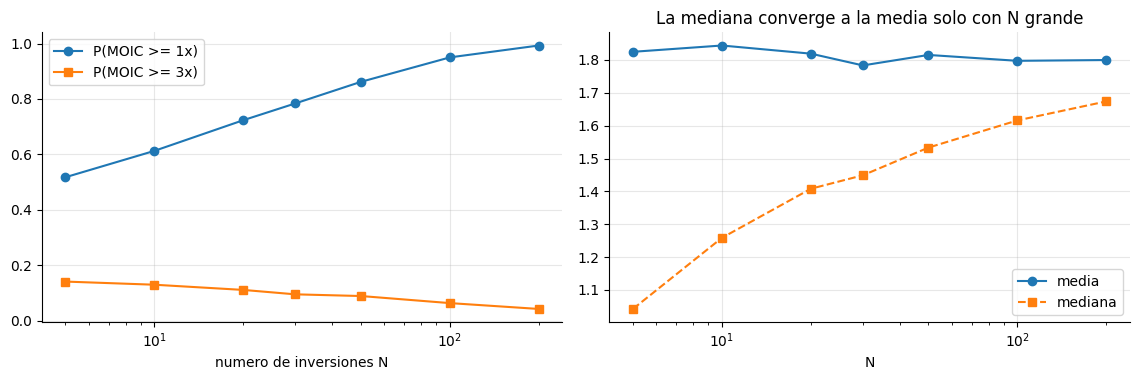

Lectura (alpha = 1.5, media por inversion 1.8x):
  Con N=10 la probabilidad de devolver el capital (MOIC>=1) es 61%; con N=30, 78%; con N=100, 95%.
  La mediana del MOIC con N=10 es 1.26x frente a una media de 1.84x: el fondo TIPICO rinde menos que el fondo ESPERADO.
  El coeficiente de variacion cae como 1/sqrt(N): de 1.95 (N=5) a 0.31 (N=200). Para CV < 0.50 hacen falta ~100 inversiones.
  El 10% de las inversiones mas exitosas aporta, en promedio, el 62% del valor del fondo (N=30).


In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.9))
ax[0].plot(fon.index, fon["P(MOIC>=1)"], "o-", label="P(MOIC >= 1x)"); ax[0].plot(fon.index, fon["P(MOIC>=3)"], "s-", label="P(MOIC >= 3x)"); ax[0].set_xscale("log"); ax[0].set_xlabel("numero de inversiones N"); ax[0].legend()
ax[1].plot(fon.index, fon["MOIC_media"], "o-", label="media"); ax[1].plot(fon.index, fon["MOIC_mediana"], "s--", label="mediana"); ax[1].set_xscale("log"); ax[1].set_xlabel("N"); ax[1].legend(); ax[1].set_title("La mediana converge a la media solo con N grande")
plt.tight_layout(); plt.show()
print("Lectura (alpha = 1.5, media por inversion 1.8x):")
print(f"  Con N=10 la probabilidad de devolver el capital (MOIC>=1) es {fon.loc[10, 'P(MOIC>=1)']:.0%}; con N=30, {fon.loc[30, 'P(MOIC>=1)']:.0%}; con N=100, {fon.loc[100, 'P(MOIC>=1)']:.0%}.")
print(f"  La mediana del MOIC con N=10 es {fon.loc[10, 'MOIC_mediana']:.2f}x frente a una media de {fon.loc[10, 'MOIC_media']:.2f}x: el fondo TIPICO rinde menos que el fondo ESPERADO.")
print(f"  El coeficiente de variacion cae como 1/sqrt(N): de {fon.loc[5, 'CV']:.2f} (N=5) a {fon.loc[200, 'CV']:.2f} (N=200). Para CV < 0.50 hacen falta ~{fon.index[(fon['CV'] < 0.50)].min()} inversiones.")
print(f"  El 10% de las inversiones mas exitosas aporta, en promedio, el {fon.loc[30, 'valor_en_top10%_inversiones']:.0%} del valor del fondo (N=30).")

## 4. Cola pesada: ¿importa el grosor a igual media?

Con la **misma media** (1,8×) por inversión, se compara la probabilidad de que un fondo de 30 inversiones devuelva el capital según $\alpha$.

In [6]:
filas = []
for alpha in (1.1, 1.3, 1.5, 2.0, 3.0):
    M = fondos(30, alpha=alpha, seed=int(alpha * 100)); moic = M.mean(axis=1)
    filas.append({"alpha": alpha, "MOIC_media": moic.mean(), "MOIC_mediana": np.median(moic), "P(MOIC>=1)": (moic >= 1).mean(), "P(MOIC>=3)": (moic >= 3).mean(), "P5": np.percentile(moic, 5), "P95": np.percentile(moic, 95)})
cola = pd.DataFrame(filas).set_index("alpha")
cola.round(3)

,MOIC_media,MOIC_mediana,P(MOIC>=1),P(MOIC>=3),P5,P95
alpha,,,,,,
1.1000,1.7900,1.2780,0.6630,0.1230,0.5200,4.9320
1.3000,1.8080,1.3680,0.7250,0.1120,0.5850,4.4520
1.5000,1.8060,1.4700,0.7840,0.0990,0.6500,3.9260
2.0000,1.7840,1.6130,0.8630,0.0710,0.7520,3.2940
3.0000,1.8010,1.7310,0.9070,0.0470,0.8460,2.9700


In [7]:
print("Lectura (N=30, media por inversion fija en 1.8x):")
print(f"  P(MOIC>=1): alpha=1.1 -> {cola.loc[1.1, 'P(MOIC>=1)']:.0%}; alpha=1.5 -> {cola.loc[1.5, 'P(MOIC>=1)']:.0%}; alpha=3 -> {cola.loc[3.0, 'P(MOIC>=1)']:.0%}.")
print(f"  La mediana del fondo baja cuando la cola es mas pesada ({cola.loc[3.0, 'MOIC_mediana']:.2f}x con alpha=3 -> {cola.loc[1.1, 'MOIC_mediana']:.2f}x con alpha=1.1): la media se sostiene por eventos cada vez mas raros.")

Lectura (N=30, media por inversion fija en 1.8x):
  P(MOIC>=1): alpha=1.1 -> 66%; alpha=1.5 -> 78%; alpha=3 -> 91%.
  La mediana del fondo baja cuando la cola es mas pesada (1.73x con alpha=3 -> 1.28x con alpha=1.1): la media se sostiene por eventos cada vez mas raros.


## 5. Reservas para *follow-on*

Se invierte inicialmente solo una parte del capital en $N$ empresas y se **reserva** el resto para invertir más en las que muestren buenas señales. Cada empresa tiene una **señal intermedia** $s$ correlacionada con su resultado final: $s=\rho\,z_X+\sqrt{1-\rho^2}\,\varepsilon$, con $z_X$ el rango normalizado del múltiplo final. Los dólares de *follow-on* entran a un precio mayor (el valor de la empresa subió): rinden $X/u$ con $u=2$ (el múltiplo del follow-on es la mitad del inicial).

Estrategias: (a) **sin reservas** (todo al inicio, $N=30$); (b) **reservas del 40 %**: inversión inicial menor en las 30 empresas y el resto repartido por igual entre el 25 % con mejor señal.

In [8]:
def fondo_con_reserva(N, rho, reserva, u, R=15_000, alpha=ALPHA, seed=0):
    rg = np.random.default_rng(seed); M = muestrear(R * N, alpha, rg).reshape(R, N)
    z = np.apply_along_axis(lambda x: stats.norm.ppf((stats.rankdata(x) - 0.5) / len(x)), 1, M)
    senal = rho * z + np.sqrt(1 - rho ** 2) * rg.standard_normal((R, N))
    inicial = (1 - reserva) / N                                                    # fraccion del fondo por empresa en la ronda inicial
    top_k = max(int(round(0.25 * N)), 1); idx = np.argsort(-senal, axis=1)[:, :top_k]
    seg = np.zeros_like(M); np.put_along_axis(seg, idx, reserva / top_k, axis=1)    # fraccion de follow-on por empresa
    valor = (inicial * M).sum(axis=1) + (seg * (M / u)).sum(axis=1)
    return valor

filas = []
for rho in (0.0, 0.2, 0.4, 0.6, 0.8):
    sin = fondo_con_reserva(30, rho, 0.0, 2.0, seed=int(rho * 100)); con = fondo_con_reserva(30, rho, 0.40, 2.0, seed=int(rho * 100))
    filas.append({"rho_senal": rho, "MOIC_sin_reserva": sin.mean(), "MOIC_con_reserva_40%": con.mean(), "diferencia": con.mean() - sin.mean(), "P(>=1)_sin": (sin >= 1).mean(), "P(>=1)_con": (con >= 1).mean()})
res = pd.DataFrame(filas).set_index("rho_senal")
res.round(3)

,MOIC_sin_reserva,MOIC_con_reserva_40%,diferencia,P(>=1)_sin,P(>=1)_con
rho_senal,,,,,
0.0000,1.8050,1.4390,-0.3660,0.7840,0.6130
0.2000,1.8070,1.5810,-0.2260,0.7870,0.6760
0.4000,1.8230,1.7760,-0.0470,0.7860,0.7440
0.6000,1.7960,1.9420,0.1460,0.7860,0.8050
0.8000,1.8280,2.1870,0.3590,0.7850,0.8630


In [9]:
rho_eq = None
for a, b in zip(res.index[:-1], res.index[1:]):
    if res.loc[a, "diferencia"] < 0 <= res.loc[b, "diferencia"]: rho_eq = a + (b - a) * (-res.loc[a, "diferencia"]) / (res.loc[b, "diferencia"] - res.loc[a, "diferencia"])
print("Lectura:")
print(f"  Sin informacion (rho=0) las reservas CUESTAN {abs(res.loc[0.0, 'diferencia']):.2f}x de MOIC: los dolares de follow-on entran mas caros (rinden X/2) y se asignan al azar.")
print(f"  Con una senal fuerte (rho=0.8) las reservas ganan {res.loc[0.8, 'diferencia']:+.2f}x.")
print(f"  Punto de equilibrio de la calidad de la senal: rho* ~ {rho_eq:.2f}." if rho_eq is not None else "  La reserva no se paga en el rango probado.")

Lectura:
  Sin informacion (rho=0) las reservas CUESTAN 0.37x de MOIC: los dolares de follow-on entran mas caros (rinden X/2) y se asignan al azar.
  Con una senal fuerte (rho=0.8) las reservas ganan +0.36x.
  Punto de equilibrio de la calidad de la senal: rho* ~ 0.45.


## 6. Del retorno bruto al neto: comisiones y *carry*

Un fondo cobra una **comisión de gestión** del 2 % anual sobre el capital comprometido durante 10 años (20 % del capital) y un ***carry*** del 20 % de las ganancias **una vez devuelto el capital más las comisiones** (cascada europea). El capital invertido es el 80 % del comprometido; el resto se va en comisiones. El MOIC bruto es sobre lo invertido; el **neto a los inversionistas (LP)** se mide sobre lo comprometido.

In [10]:
def neto(moic_bruto, comis=0.02, anos=10, carry=0.20):
    comprometido = 1.0; comisiones = comis * anos; invertido = comprometido - comisiones
    valor = invertido * moic_bruto                                          # distribuciones brutas
    base = comprometido                                                     # devolver capital comprometido (incluye comisiones)
    ganancia = np.maximum(valor - base, 0); carry_pagado = carry * ganancia
    return (valor - carry_pagado) / comprometido

M = fondos(30, seed=99); bruto = M.mean(axis=1); net = neto(bruto)
tab = pd.DataFrame({"bruto": bruto, "neto_LP": net}).describe(percentiles=[.05, .25, .5, .75, .95]).T[["mean", "5%", "50%", "95%"]]
tab["P(>=1)"] = [(bruto >= 1).mean(), (net >= 1).mean()]
print(f"Probabilidad de que el MOIC neto de los LP sea menor que 1: {(net < 1).mean():.0%}")
tab.round(3)

Probabilidad de que el MOIC neto de los LP sea menor que 1: 37%


,mean,5%,50%,95%,P(>=1)
bruto,1.8110,0.6390,1.4610,4.0050,0.7850
neto_LP,1.3390,0.5110,1.1350,2.7630,0.6280


In [11]:
print("Lectura (N=30, alpha=1.5):")
print(f"  MOIC medio: bruto {bruto.mean():.2f}x -> neto {net.mean():.2f}x. Las comisiones y el carry se llevan {(1 - net.mean() / bruto.mean()) * 100:.0f}% del retorno bruto medio.")
print(f"  La mediana neta es {np.median(net):.2f}x (bruta {np.median(bruto):.2f}x): el fondo tipico apenas supera el capital, mientras la media la sostienen pocos fondos muy buenos.")
print(f"  P(neto >= 1): {(net >= 1).mean():.0%} frente a P(bruto >= 1): {(bruto >= 1).mean():.0%}.")

Lectura (N=30, alpha=1.5):
  MOIC medio: bruto 1.81x -> neto 1.34x. Las comisiones y el carry se llevan 26% del retorno bruto medio.
  La mediana neta es 1.13x (bruta 1.46x): el fondo tipico apenas supera el capital, mientras la media la sostienen pocos fondos muy buenos.
  P(neto >= 1): 63% frente a P(bruto >= 1): 79%.


## 7. Suerte frente a habilidad: persistencia entre fondos

Si el desempeño de los gestores dependiera de la **habilidad**, quien rinde bien en el fondo I debería rendir bien en el fondo II. Se simulan 500 gestores con $N=25$ inversiones por fondo. La habilidad $\theta_m\sim N(0,\sigma^2)$ desplaza la probabilidad de **ganadora** del gestor ($p=0{,}2\,e^{\theta_m}$) de forma **persistente** entre fondos. Con $\sigma=0$ todos son idénticos y toda la diferencia es **suerte**.

In [12]:
def moic_gestores(sigma, M_=500, N=25, alpha=ALPHA, seed=0):
    rg = np.random.default_rng(seed); theta = rg.normal(0, sigma, M_); pg = np.clip(0.20 * np.exp(theta), 0.02, 0.6)
    def fondo():
        out = np.empty(M_)
        for m in range(M_):
            u = rg.random(N); X = np.zeros(N); gan = u < pg[m]; parc = (u >= pg[m]) & (u < pg[m] + 0.30)
            X[parc] = rg.uniform(0.3, 1.0, parc.sum()); v = rg.random(gan.sum()); X[gan] = escala(alpha) * (1 - v * (1 - CAP ** (-alpha))) ** (-1 / alpha); out[m] = X.mean()
        return out
    return fondo(), fondo()

filas = []
for sigma in (0.0, 0.15, 0.30, 0.60):
    c1, c2 = [], []; top_rep = []
    for rep in range(12):
        f1, f2 = moic_gestores(sigma, seed=1000 * rep + int(sigma * 100))
        c1.append(stats.spearmanr(f1, f2)[0]); q1 = f1 >= np.quantile(f1, 0.75); q2 = f2 >= np.quantile(f2, 0.75); top_rep.append((q1 & q2).sum() / q1.sum())
    filas.append({"sigma_habilidad": sigma, "correlacion_fondoI_fondoII": np.mean(c1), "P(cuartil superior se repite)": np.mean(top_rep)})
pers = pd.DataFrame(filas).set_index("sigma_habilidad")
pers.round(3)

,correlacion_fondoI_fondoII,P(cuartil superior se repite)
sigma_habilidad,,
0.0000,-0.0110,0.2480
0.1500,0.0770,0.2810
0.3000,0.2080,0.3370
0.6000,0.5160,0.5210


In [13]:
print("Lectura (cuartil superior esperado por azar puro: 25%):")
print(f"  Con habilidad CERO, la correlacion entre fondos es {pers.loc[0.0, 'correlacion_fondoI_fondoII']:+.2f} y el {pers.loc[0.0, 'P(cuartil superior se repite)']:.0%} del cuartil superior se repite (azar = 25%).")
print(f"  Con una dispersion de habilidad sustancial (sigma=0.6, que cambia la tasa de ganadoras de 20% a un rango de ~11%-36%), la correlacion sube a {pers.loc[0.6, 'correlacion_fondoI_fondoII']:+.2f} y la repeticion del cuartil superior a {pers.loc[0.6, 'P(cuartil superior se repite)']:.0%}.")
print("  Aun con habilidad real, la persistencia es modesta porque el resultado de un fondo de 25 inversiones es MUY ruidoso: elegir gestores por el ultimo fondo premia mucha suerte.")

Lectura (cuartil superior esperado por azar puro: 25%):
  Con habilidad CERO, la correlacion entre fondos es -0.01 y el 25% del cuartil superior se repite (azar = 25%).
  Con una dispersion de habilidad sustancial (sigma=0.6, que cambia la tasa de ganadoras de 20% a un rango de ~11%-36%), la correlacion sube a +0.52 y la repeticion del cuartil superior a 52%.
  Aun con habilidad real, la persistencia es modesta porque el resultado de un fondo de 25 inversiones es MUY ruidoso: elegir gestores por el ultimo fondo premia mucha suerte.


## 8. Pruebas automáticas

In [14]:
# 8.1 la media simulada coincide con la calibrada para todo alpha, y la media de la Pareto truncada coincide con una integracion numerica
assert np.abs(verif["media_simulada"] - MU_OBJ).max() < 0.15
from scipy.integrate import quad
for al in (1.1, 1.5, 3.0):
    dens = lambda y: al * y ** (-al - 1) / (1 - CAP ** (-al)); num = quad(lambda y: y * dens(y), 1, CAP, limit=300)[0]
    assert abs(num - media_pareto_trunc(al)) < 1e-6
# 8.2 la probabilidad de devolver el capital crece con el numero de inversiones; el CV baja como 1/sqrt(N)
assert fon["P(MOIC>=1)"].is_monotonic_increasing and fon["CV"].is_monotonic_decreasing
assert abs(np.polyfit(np.log(fon.index), np.log(fon["CV"]), 1)[0] + 0.5) < 0.12
# 8.3 la mediana es menor que la media con N pequeno y converge a ella con N grande
assert fon.loc[10, "MOIC_mediana"] < fon.loc[10, "MOIC_media"] - 0.2 and abs(fon.loc[200, "MOIC_mediana"] - fon.loc[200, "MOIC_media"]) < 0.25
# 8.4 la media del fondo coincide con la media por inversion para todo N
assert (np.abs(fon["MOIC_media"] - MU_OBJ) < 0.12).all()
# 8.5 cola mas pesada: mediana del fondo menor a igual media
assert cola.loc[1.1, "MOIC_mediana"] < cola.loc[3.0, "MOIC_mediana"] and cola.loc[1.1, "P(MOIC>=1)"] < cola.loc[3.0, "P(MOIC>=1)"]
# 8.6 reservas: con senal nula cuestan, con senal fuerte ganan, y la diferencia crece con la calidad de la senal
assert res.loc[0.0, "diferencia"] < 0 < res.loc[0.8, "diferencia"] and res["diferencia"].is_monotonic_increasing
assert rho_eq is not None and 0.0 < rho_eq < 0.8
# 8.7 comisiones y carry: el neto es menor que el bruto y la probabilidad de neto>=1 es menor que la de bruto>=1
assert (net <= bruto * 0.8 + 1e-12).all() or (net < bruto).all()
assert (net >= 1).mean() < (bruto >= 1).mean() and net.mean() < bruto.mean()
assert abs(neto(np.array([1.0]))[0] - 0.8) < 1e-12 and abs(neto(np.array([0.0]))[0]) < 1e-12
# 8.8 persistencia: con habilidad cero la correlacion es ~0 y el cuartil superior se repite ~25%; crece con la dispersion de habilidad
assert abs(pers.loc[0.0, "correlacion_fondoI_fondoII"]) < 0.1 and abs(pers.loc[0.0, "P(cuartil superior se repite)"] - 0.25) < 0.08
assert pers["correlacion_fondoI_fondoII"].iloc[-1] > pers["correlacion_fondoI_fondoII"].iloc[0] + 0.1 and pers["P(cuartil superior se repite)"].iloc[-1] > 0.3
print("Todas las pruebas pasaron.")

Todas las pruebas pasaron.


## Conclusiones y límites

| Paso | Qué se encontró | Decisión |
|---|---|---|
| Modelo por inversión | Pérdida total, devoluciones parciales y una cola de Pareto truncada con media calibrada y verificada | Verificar la media calibrada contra la fórmula cerrada y la simulación |
| Diversificación | La probabilidad de devolver el capital sube con el número de inversiones; el coeficiente de variación baja como 1/√N | Con pocas inversiones el fondo típico rinde menos que el esperado |
| Cola pesada | A igual media, una cola más pesada baja la mediana y la probabilidad de devolver el capital | No confundir el retorno esperado con el retorno típico |
| Reservas | Se pagan solo si la señal intermedia es suficientemente informativa; sin información cuestan | Reservar solo si hay evidencia de que las señales predicen |
| Comisiones y carry | Se llevan una parte importante del retorno bruto y el fondo típico apenas supera el capital | Mirar el retorno neto y su mediana, no el bruto medio |
| Suerte y habilidad | Con habilidad cero, el desempeño no persiste entre fondos; con habilidad real, la persistencia es modesta | No elegir gestores solo por su último fondo |

**Límites que no deben ocultarse**

- El modelo por inversión (probabilidades y cola) es estilizado; los retornos reales dependen de la etapa, el sector y el ciclo.
- Se supone independencia entre inversiones; en la realidad hay correlación por ciclo de mercado que reduce el beneficio de la diversificación.
- El modelo de reservas usa una señal gaussiana y un precio de entrada del follow-on fijo (el doble); varía mucho entre fondos.
- La cascada de comisiones es una simplificación (sin tasa mínima de retorno ni plazos de distribución).
- Datos sintéticos: ningún valor numérico es extrapolable a un fondo real.